
# H2 Native-Noise Benchmark for the 3-Qubit Repetition Code

This notebook compares three strategies under the **H2-Emulator native noise model**:

1. **Bare physical qubit**: prepare $|0\rangle$ and measure.
2. **Encoded, no active QEC**: prepare $|000\rangle$, then decode only by final majority vote.
3. **Encoded + active QEC**: measure the two repetition-code syndromes, apply a classically conditioned correction, then perform final majority-vote decoding.

There is **no deliberately injected $X$ error** in this benchmark.

The backend is

```python
H2-Emulator
noisy_simulation=True
```

so the experiment focuses on the H2 emulator noise model and the extra circuit overhead introduced by active QEC.



## QEC logic

For the repetition code,

$$
|0_L\rangle = |000\rangle .
$$

The parity checks are

$$
s_0=d_0\oplus d_1,\qquad s_1=d_1\oplus d_2.
$$

The real-time lookup decoder is:

| Syndrome $(s_0,s_1)$ | Register value | Correction |
|---|---:|---|
| $(0,0)$ | 0 | none |
| $(1,0)$ | 1 | $X_0$ |
| $(1,1)$ | 3 | $X_1$ |
| $(0,1)$ | 2 | $X_2$ |

A final logical failure occurs when at least two of the three measured data bits are 1.


In [1]:

# ============================================================
# 1. Imports, settings, and Nexus project
# ============================================================

import time
import uuid

import pandas as pd
import matplotlib.pyplot as plt
import qnexus as qnx

from pytket.circuit import Circuit
from pytket.circuit.logic_exp import reg_eq

N_SHOTS = 10_000
POLL_SECONDS = 10

suffix = str(uuid.uuid4())[:8]

project = qnx.projects.get_or_create(
    name="QEC H2 Native Noise Benchmark"
)
qnx.context.set_active_project(project)

config = qnx.QuantinuumConfig(
    device_name="H2-Emulator",
    noisy_simulation=True
)

print("Project:", project.annotations.name)
print("Shots per circuit:", N_SHOTS)
print("Backend: H2-Emulator, noisy_simulation=True")


Project: QEC H2 Native Noise Benchmark
Shots per circuit: 10000
Backend: H2-Emulator, noisy_simulation=True


In [2]:

# ============================================================
# 2. Job helpers
# ============================================================

def _status_value(status):
    return str(getattr(status.status, "value", status.status))


def wait_with_status(job, label, poll_seconds=POLL_SECONDS):
    last = None

    while True:
        status = qnx.jobs.status(job)
        value = _status_value(status)

        if value != last:
            print(f"{label}: {value}", flush=True)
            last = value

        if value in {"COMPLETED", "ERROR", "CANCELLED"}:
            return status

        time.sleep(poll_seconds)


def require_completed(label, status):
    if _status_value(status) != "COMPLETED":
        raise RuntimeError(f"{label} failed or was cancelled:\n{status}")


In [3]:

# ============================================================
# 3. Build the three benchmark circuits
# ============================================================

# A. Bare physical qubit
physical = Circuit()
physical.name = "physical-zero"

qp = physical.add_q_register("q", 1)
cp = physical.add_c_register("out", 1)

physical.Measure(qp[0], cp[0])


# B. Encoded |000>, no active QEC
encoded = Circuit()
encoded.name = "encoded-no-active-qec"

qe = encoded.add_q_register("data", 3)
ce = encoded.add_c_register("out", 3)

for i in range(3):
    encoded.Measure(qe[i], ce[i])


# C. Encoded |000> + one active-QEC round
qec = Circuit()
qec.name = "encoded-active-qec"

data = qec.add_q_register("data", 3)
anc = qec.add_q_register("ancilla", 1)

syndrome = qec.add_c_register("syndrome", 2)
out = qec.add_c_register("output", 3)

# Measure Z0 Z1
qec.CX(data[0], anc[0])
qec.CX(data[1], anc[0])
qec.Measure(anc[0], syndrome[0])
qec.Reset(anc[0])

# Measure Z1 Z2
qec.CX(data[1], anc[0])
qec.CX(data[2], anc[0])
qec.Measure(anc[0], syndrome[1])
qec.Reset(anc[0])

# Lookup decoder
qec.X(data[0], condition=reg_eq(syndrome, 1))
qec.X(data[1], condition=reg_eq(syndrome, 3))
qec.X(data[2], condition=reg_eq(syndrome, 2))

for i in range(3):
    qec.Measure(data[i], out[i])

print("Built 3 circuits:")
print("  1) Physical")
print("  2) Encoded + final majority")
print("  3) Active QEC")


Built 3 circuits:
  1) Physical
  2) Encoded + final majority
  3) Active QEC


In [4]:

# ============================================================
# 4. Upload, compile, and execute as one batch
# ============================================================

records = [
    {
        "label": "Physical",
        "kind": "physical",
        "circuit": physical,
        "bits": [cp[0]],
    },
    {
        "label": "Encoded + majority",
        "kind": "encoded",
        "circuit": encoded,
        "bits": [ce[0], ce[1], ce[2]],
    },
    {
        "label": "Active QEC",
        "kind": "encoded",
        "circuit": qec,
        "bits": [out[0], out[1], out[2]],
    },
]

program_refs = []

for i, rec in enumerate(records):
    ref = qnx.circuits.upload(
        circuit=rec["circuit"],
        name=f"h2-native-{i}-{suffix}"
    )
    program_refs.append(ref)

print("Uploaded", len(program_refs), "circuits")

compile_job = qnx.start_compile_job(
    programs=program_refs,
    backend_config=config,
    optimisation_level=0,
    name=f"h2-native-compile-{suffix}"
)

compile_status = wait_with_status(compile_job, "Compilation")
require_completed("Compilation", compile_status)

compiled_refs = [
    result.get_output()
    for result in qnx.jobs.results(compile_job)
]

execute_job = qnx.start_execute_job(
    programs=compiled_refs,
    backend_config=config,
    n_shots=[N_SHOTS] * len(compiled_refs),
    name=f"h2-native-execute-{suffix}"
)

execute_status = wait_with_status(execute_job, "Execution")
require_completed("Execution", execute_status)

job_results = qnx.jobs.results(execute_job)

print("Benchmark execution completed.")


Uploaded 3 circuits
Compilation: SUBMITTED
Compilation: QUEUED
Compilation: COMPLETED
Execution: SUBMITTED
Execution: RUNNING
Execution: COMPLETED
Benchmark execution completed.


In [5]:

# ============================================================
# 5. Analyse the error rates
# ============================================================

def majority_failure_rate(counts, shots):
    failures = sum(
        count
        for bits, count in counts.items()
        if sum(bits) >= 2
    )
    return failures / shots


rows = []

for rec, job_result in zip(records, job_results):
    result = job_result.download_result()
    counts = result.get_counts(rec["bits"])

    if rec["kind"] == "physical":
        error_rate = counts.get((1,), 0) / N_SHOTS
    else:
        error_rate = majority_failure_rate(counts, N_SHOTS)

    rows.append({
        "Strategy": rec["label"],
        "Error rate": error_rate,
        "Counts": counts,
    })

summary_df = pd.DataFrame(
    [
        {
            "Strategy": row["Strategy"],
            "Error rate": row["Error rate"],
        }
        for row in rows
    ]
)

display(summary_df)

for row in rows:
    print(f"\n=== {row['Strategy']} ===")
    print(row["Counts"])
    print("Error rate =", row["Error rate"])


,Strategy,Error rate
0,Physical,0.0005
1,Encoded + majority,0.0000
2,Active QEC,0.0014



=== Physical ===
Counter({(0,): 9995, (1,): 5})
Error rate = 0.0005

=== Encoded + majority ===
Counter({(0, 0, 0): 9982, (0, 1, 0): 11, (0, 0, 1): 5, (1, 0, 0): 2})
Error rate = 0.0

=== Active QEC ===
Counter({(0, 0, 0): 9923, (0, 0, 1): 30, (1, 0, 0): 25, (0, 1, 1): 13, (0, 1, 0): 8, (1, 1, 0): 1})
Error rate = 0.0014


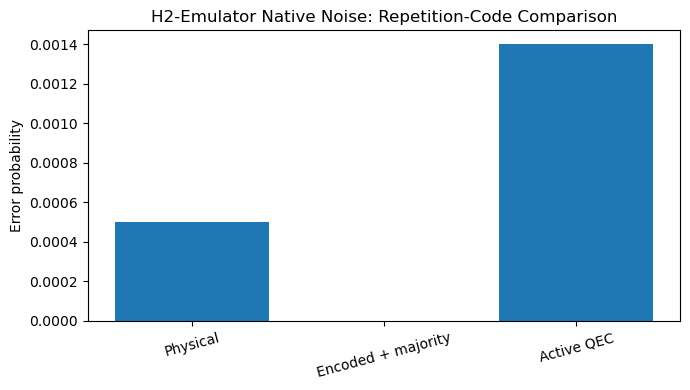

In [6]:

# ============================================================
# 6. Compact comparison plot
# ============================================================

plt.figure(figsize=(7, 4))
plt.bar(
    summary_df["Strategy"],
    summary_df["Error rate"]
)
plt.ylabel("Error probability")
plt.title("H2-Emulator Native Noise: Repetition-Code Comparison")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()



## Interpretation

This is a **short-circuit native-noise benchmark**, not a threshold experiment.

The important comparison is the circuit overhead:

- **Encoded + majority** adds redundancy but no syndrome-extraction circuit.
- **Active QEC** additionally uses four data-ancilla CNOTs, two mid-circuit measurements, resets, and conditional corrections.

For a short experiment with already-low native error rates, active QEC does not have to outperform the simpler encoded strategy. The role of repeated active correction becomes clearer when errors accumulate over multiple rounds.
